<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Survival analysis](https://github.com/Query-farm/vgi-survival)

Estimate survival curves, hazard ratios and log-rank tests from time-to-event data.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-survival/blob/main/notebooks/02_hazard_ratios_need_a_unit.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-survival/blob/main/notebooks/README.md)

## 02 · A hazard ratio needs a unit

Compare two questions about **80 simulated devices**: do the low/high-load groups
have different follow-up curves, and how does a Cox model express a continuous
load increment? Then halve that increment without changing any device record.
The reported hazard ratio changes; the modeled relationship does not.

All durations, loads and outcomes are generated for this example. They are not
field measurements. A fixed seed makes this an auditable computation, not evidence
of a causal load effect or a reliability estimate for a real device population.

### Choose the increment, leaving observations fixed

`LOAD_STEP` is **10** percentage points by default; the experiment uses **5**.
Only the covariate units change. The allowed values are integer 5 and 10.
The low/high group boundary stays at 50% load in both runs.

In [1]:
LOAD_STEP = 10  # Percentage points per covariate unit; experiment: 5

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.24":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.24"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("survival")
import survival_example as example  # noqa: E402 — download before import

manifest = example.configure(LOAD_STEP, mode="load")
theme()
session = connect(globals())
connection = session.connection

### Connect to public release v0.4.0

The worker runs through `uvx` in an isolated environment. SQL projects the role
columns explicitly: all columns other than duration/event become Cox covariates.
An ID or group label must not accidentally enter that fit.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'survival' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-survival@v0.4.0 vgi-survival-worker');

,Success


### Choose the method for the question

The native `methods` view separates curve estimation, group comparison and
regression. Here log-rank compares the two entire group curves; Cox estimates a
continuous load coefficient. A group-test p-value is not an effect size, and a
hazard ratio is neither an event probability nor a ratio of median times.

In [5]:
%%sql
SELECT method,category,question,returns FROM survival.main.methods ORDER BY category,method;

,method,category,question,returns
0,logrank_test,comparison,Do two or more groups have different survival?,"One row: the chi-squared statistic, the p-valu..."
1,kaplan_meier,estimation,How does an event-free population decline over...,One row per distinct follow-up time: survival ...
2,median_survival,estimation,What single headline time summarizes a cohort'...,One row: the median survival time where the Ka...
3,cox_hazard_ratios,regression,How does each covariate raise or lower the haz...,"One row per covariate: coefficient, hazard rat..."


### Keep censoring and the population visible

The generator uses an exponential event-time model with load-dependent rate,
then an independently drawn observation stop. Recorded duration is the earlier
time; `event=1` only when the event occurred first. The committed fixture and
provenance include its seed and algorithm; both are hash-checked before use.
The generator does not fit any estimator or store the expected fitted answers.

SQL divides load by the chosen increment. No grouping, duration or event label
changes in the experiment. The 50% boundary is an authored illustration, not an
estimated best split.

In [6]:
%%sql
CREATE TABLE device_data AS SELECT * FROM read_csv('fixtures/load_followup.csv',header=true,
 columns={'device_id':'VARCHAR','load_pct':'INTEGER','duration_days':'DOUBLE','event':'INTEGER'});
CREATE TABLE cohort AS SELECT *,load_pct::DOUBLE/{{ LOAD_STEP }} AS load_units,
 CASE WHEN load_pct<50 THEN 'Below 50%' ELSE '50% or above' END AS load_group FROM device_data;
CREATE TABLE group_summary AS SELECT load_group,count(*) AS devices,sum(event) AS failures,
 count(*)-sum(event) AS censored,min(load_pct) AS min_load_pct,max(load_pct) AS max_load_pct
 FROM cohort GROUP BY load_group;
SELECT * FROM group_summary ORDER BY load_group;

,load_group,devices,failures,censored,min_load_pct,max_load_pct
0,50% or above,42,29.0,13.0,50,80
1,Below 50%,38,11.0,27.0,20,45


### Compare the group curves with log-rank

Both Kaplan–Meier calls use only duration and event. Each curve stops at its
last recorded follow-up; confidence bands are pointwise, not simultaneous.
Log-rank uses the whole two-group relation and the named `"group"` argument.
Its null concerns the group survival distributions. These simulated p-values
are numerical examples; no threshold is used to label a real-world claim.

In [7]:
%%sql
CREATE TABLE group_curves AS
 SELECT 'Below 50%' AS load_group,* FROM survival.main.kaplan_meier(
  (SELECT duration_days,event FROM cohort WHERE load_group='Below 50%'),duration:='duration_days',event:='event')
 UNION ALL SELECT '50% or above',* FROM survival.main.kaplan_meier(
  (SELECT duration_days,event FROM cohort WHERE load_group='50% or above'),duration:='duration_days',event:='event');
CREATE TABLE group_test AS SELECT * FROM survival.main.logrank_test(
 (SELECT duration_days,event,load_group FROM cohort),duration:='duration_days',event:='event',"group":='load_group');
SELECT * FROM group_test;

,test_statistic,p_value,degrees_freedom
0,11.942731,0.000549,1


,test_statistic,p_value,degrees_freedom
0,11.942731,0.000549,1


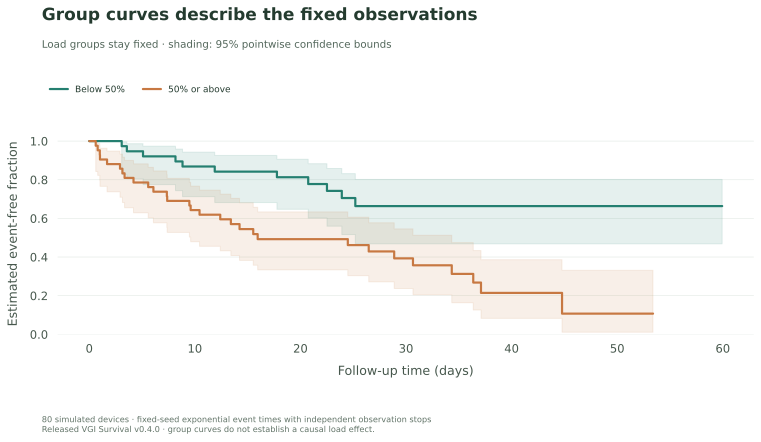

The log-rank statistic is **11.943** with **1 degree of freedom**, and p = **0.000549**. It describes this fixed grouping of the synthetic input. It does not report a hazard ratio, identify a causal effect, or check proportional hazards.

In [8]:
curves = connection.execute("SELECT * FROM group_curves ORDER BY load_group,time").df()
comparison = connection.execute("SELECT * FROM group_test").df()
display(comparison)
example.plot_groups(curves)
r = comparison.iloc[0]
prose(
    f"The log-rank statistic is **{r.test_statistic:.3f}** with **{int(r.degrees_freedom)} degree of freedom**, "
    f"and p = **{r.p_value:.3g}**. It describes this fixed grouping of the synthetic input. "
    "It does not report a hazard ratio, identify a causal effect, or check proportional hazards."
)

### Fit a continuous load effect and normalize its units

One covariate unit equals `LOAD_STEP` percentage points. The returned hazard ratio
is `exp(coef)` for that increment, with a default 95% interval on the same ratio
scale. To compare runs, SQL raises the ratio and interval endpoints to
`10 / LOAD_STEP`, expressing a common **ten-percentage-point** contrast.

A second fixed-unit fit is an independent call through the worker and checks this
rescaling identity. A unit conversion is not a model adequacy check. Cox assumes
a proportional hazard relationship; this notebook does not diagnose that assumption
or recover a causal effect from observed data.

In [9]:
%%sql
CREATE TABLE selected_fit AS SELECT * FROM survival.main.cox_hazard_ratios(
 (SELECT duration_days,event,load_units FROM cohort),duration:='duration_days',event:='event');
CREATE TABLE reference_fit AS SELECT * FROM survival.main.cox_hazard_ratios(
 (SELECT duration_days,event,load_pct::DOUBLE/10 AS load_units FROM cohort),duration:='duration_days',event:='event');
CREATE TABLE unit_comparison AS
 SELECT {{ LOAD_STEP }} AS selected_step_pct,s.coef,s.hazard_ratio,s.ci_lower,s.ci_upper,s.p_value,
 pow(s.hazard_ratio,10.0/{{ LOAD_STEP }}) AS hr_per_ten,
 pow(s.ci_lower,10.0/{{ LOAD_STEP }}) AS lower_per_ten,
 pow(s.ci_upper,10.0/{{ LOAD_STEP }}) AS upper_per_ten,
 r.coef AS reference_coef,r.hazard_ratio AS reference_hr,
 r.ci_lower AS reference_lower,r.ci_upper AS reference_upper,r.p_value AS reference_p
 FROM selected_fit s CROSS JOIN reference_fit r;
SELECT * FROM unit_comparison;

,selected_step_pct,coef,hazard_ratio,ci_lower,ci_upper,p_value,hr_per_ten,lower_per_ten,upper_per_ten,reference_coef,reference_hr,reference_lower,reference_upper,reference_p
0,10,0.301324,1.351648,1.139201,1.603713,0.000553,1.351648,1.139201,1.603713,0.301324,1.351648,1.139201,1.603713,0.000553


,selected_step_pct,coef,hazard_ratio,ci_lower,ci_upper,p_value,hr_per_ten,lower_per_ten,upper_per_ten,reference_coef,reference_hr,reference_lower,reference_upper,reference_p
0,10,0.301324,1.351648,1.139201,1.603713,0.000553,1.351648,1.139201,1.603713,0.301324,1.351648,1.139201,1.603713,0.000553


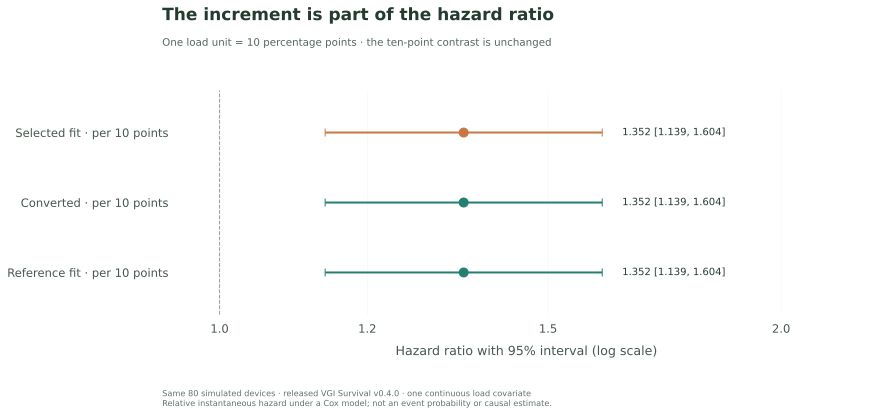

A **10-point** increase is reported as hazard ratio **1.352** (95% interval **1.139–1.604**). Expressed per **10 points**, it is **1.352**, matching the fixed-unit fit. This is a relative instantaneous hazard under the fitted model, not the probability of failure by a date.

In [10]:
fit = connection.execute("SELECT * FROM unit_comparison").df()
display(fit)
example.plot_ratios(fit, LOAD_STEP)
f = fit.iloc[0]
prose(
    f"A **{LOAD_STEP}-point** increase is reported as hazard ratio **{f.hazard_ratio:.3f}** "
    f"(95% interval **{f.ci_lower:.3f}–{f.ci_upper:.3f}**). Expressed per **10 points**, "
    f"it is **{f.hr_per_ten:.3f}**, matching the fixed-unit fit. "
    "This is a relative instantaneous hazard under the fitted model, not the probability of failure by a date."
)

### Verify the population and the unit-conversion identity

These controls reconcile sample counts, event coding, curve bounds, the two-group
test degrees of freedom and Cox coefficient/ratio identities. All three rescaled
ratio quantities and the Wald p-value must agree with the fixed-unit fit within
numerical tolerance. They establish correct use of the interface, not validity
for an external population.

In [11]:
%%sql checks <<
SELECT '80 unique devices preserved' AS check_name,
 (SELECT count(*)=80 AND count(DISTINCT device_id)=80 FROM cohort) AS passed
UNION ALL SELECT 'valid duration and event coding',(SELECT bool_and(duration_days>0 AND event IN (0,1)) FROM cohort)
UNION ALL SELECT 'each group has events and censoring',
 (SELECT count(*)=2 AND bool_and(failures>0 AND censored>0 AND devices=failures+censored) FROM group_summary)
UNION ALL SELECT 'load units retain the exact input',
 (SELECT bool_and(abs(load_units*{{ LOAD_STEP }}-load_pct)<1e-10) FROM cohort)
UNION ALL SELECT 'two curves start at one',(SELECT count(*)=2 AND bool_and(survival=1) FROM group_curves WHERE time=0)
UNION ALL SELECT 'curves bounded and nonincreasing',
 (SELECT bool_and(survival BETWEEN 0 AND 1 AND (previous IS NULL OR survival<=previous+1e-12))
 FROM(SELECT *,lag(survival) OVER(PARTITION BY load_group ORDER BY time) AS previous FROM group_curves))
UNION ALL SELECT 'curve bounds contain estimates',
 (SELECT bool_and(ci_lower<=survival+1e-12 AND ci_upper>=survival-1e-12) FROM group_curves)
UNION ALL SELECT 'one two-group test result',
 (SELECT count(*)=1 AND bool_and(degrees_freedom=1 AND test_statistic>=0 AND p_value BETWEEN 0 AND 1) FROM group_test)
UNION ALL SELECT 'one intended Cox covariate',(SELECT count(*)=1 AND bool_and(covariate='load_units') FROM selected_fit)
UNION ALL SELECT 'ratio is exp coefficient',(SELECT abs(hazard_ratio-exp(coef))<1e-9 FROM selected_fit)
UNION ALL SELECT 'coefficient rescales',(SELECT abs(coef*10.0/{{ LOAD_STEP }}-reference_coef)<1e-7 FROM unit_comparison)
UNION ALL SELECT 'rescaled ratio and interval match reference',
 (SELECT abs(hr_per_ten-reference_hr)<1e-7 AND abs(lower_per_ten-reference_lower)<1e-7
 AND abs(upper_per_ten-reference_upper)<1e-7 FROM unit_comparison)
UNION ALL SELECT 'Wald p unchanged',(SELECT abs(p_value-reference_p)<1e-8 FROM unit_comparison);

In [12]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
prose(f"**{len(checks)} SQL checks passed.** Fixture hashes were verified before attachment.")

,check_name,passed
0,80 unique devices preserved,True
1,valid duration and event coding,True
2,each group has events and censoring,True
3,load units retain the exact input,True
4,two curves start at one,True
5,curves bounded and nonincreasing,True
6,curve bounds contain estimates,True
7,one two-group test result,True
8,one intended Cox covariate,True
9,ratio is exp coefficient,True


**13 SQL checks passed.** Fixture hashes were verified before attachment.

### Experiment: report the same model per five load points

Change only `LOAD_STEP` from **10 to 5** and run all. Predict the coefficient
will halve, the hazard ratio and interval endpoints will become square roots,
and the p-value and ten-point contrast will remain fixed. The group curves and
log-rank result must also remain unchanged because their inputs are unchanged.

```sh
uv run --locked vgi-notebooks 02_hazard_ratios_need_a_unit.ipynb \
 --parameters '{"LOAD_STEP":5}' --output-dir artifacts/five-point-load
```

Restore **10**. Reporting a ratio without its covariate increment makes this
perfectly consistent change look like a change in the estimated relationship.

In [13]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-survival](https://github.com/Query-farm/vgi-survival)